# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.Fm Linear Regression Notebook
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 17th October 2026*

---

This notebook explores a linear regression question using Last.fm scrobbles merged with Spotify track features:

- Does the average release year of music I scrobble change from week to week?


Every scrobble is joined to its track's Spotify features, using the same cleaning functions as the collection notebook, with times converted to Dublin local time


### Load and prepare the scrobble data

Load the raw scrobbles and the merged track features, clean the artist and track names so the two files can be joined, and keep only plays that matched with a Spotify track. Dates are converted to Dublin time so weeks line up with my actual day

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import numpy as np
from data_clean import clean_text, clean_artist

audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']
tags = ['release_year', 'popularity', 'artist_popularity', 'explicit']

plays = pd.read_csv('../datasets/scrobbles.csv')
scrobbles = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

# dublin time
local = pd.to_datetime(plays['date']).dt.tz_localize('UTC').dt.tz_convert('Europe/Dublin')
plays['local_time'] = local.dt.tz_localize(None)
plays['local_date'] = plays['local_time'].dt.normalize()

plays['clean_track'] = clean_text(plays['song'])
plays['clean_artist'] = clean_artist(plays['artist'])

# one row per unique track with its Spotify features
scrobbles_unique = scrobbles.drop_duplicates(['clean_artist', 'clean_track']).copy()

# every play that could be matched to Spotify features
plays_feat = plays.merge(scrobbles_unique[['clean_artist', 'clean_track'] + audio + tags],
                         on=['clean_artist', 'clean_track'], how='inner')

print(f"All scrobbles:                  {len(plays):,}")
print(f"Scrobbles matched to Spotify:   {len(plays_feat):,}  ({len(plays_feat) / len(plays):.1%} of plays)")
print(f"Unique tracks:                  {len(scrobbles_unique):,}  ")
print(f"Listening window:               {plays['local_date'].min().date()} to {plays['local_date'].max().date()}")

All scrobbles:                  17,999
Scrobbles matched to Spotify:   14,629  (81.3% of plays)
Unique tracks:                  1,838  
Listening window:               2025-11-18 to 2026-10-14


### Fit a linear trend to weekly averages

This cell groups scrobbles by week and calculates the average release year of tracks played each week.

It uses week as the predictor and average release year as the response, then fits a straight line.

The slope describes weekly change, R-squared describes how much of the variation the line accounts for. The plot shows the observed averages and fitted trend

- Weeks with very few matched plays give weird averages, so weeks below `min_plays` are dropped 
- Time is measured in **years** not days or weeks, so the slope is readable easily

Slope (Years changed per year):  1.757
Intercept:                       2003.3
R-squared:                       0.0243
Weeks analysed:                  48


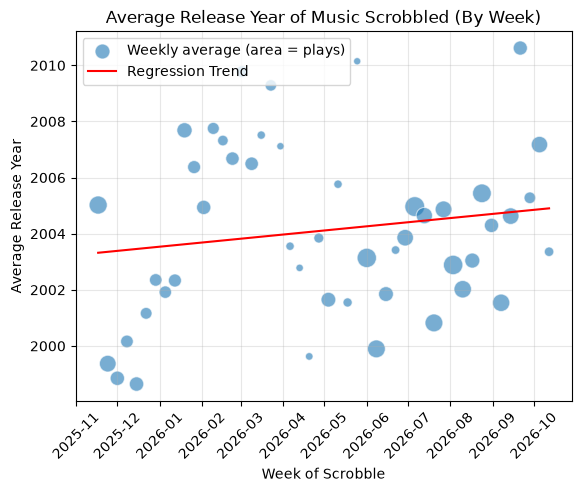

In [7]:
# create a week col starts on Mondays
plays_feat['week'] = plays_feat['local_time'].dt.to_period('W').dt.start_time

# calculate the average release year
weekly_trend = plays_feat.groupby('week').agg(
    avg_release_year=('release_year', 'mean'),
    scrobble_count=('release_year', 'size'),
).reset_index()

# drop anything with lower than min_plays
min_plays = 25
weekly_trend = weekly_trend[weekly_trend['scrobble_count'] >= min_plays].reset_index(drop=True)
weekly_trend['years_since_start'] = (weekly_trend['week'] - weekly_trend['week'].min()).dt.days / 365.25

X = weekly_trend[['years_since_start']]
y = weekly_trend['avg_release_year']

# referenced Linear-Regression.ipynb:
# fit the estimator, then use predict() and score() for model evaluation
model = LinearRegression()
model.fit(X, y)

print(f"Slope (Years changed per year):  {model.coef_[0]:.3f}")
print(f"Intercept:                       {model.intercept_:.1f}")
print(f"R-squared:                       {model.score(X, y):.4f}")
print(f"Weeks analysed:                  {len(weekly_trend)}")

# size of each dot is proportional to the number of plays behind that week's average
plt.scatter(weekly_trend['week'], y, s=weekly_trend['scrobble_count'] / 3,
            alpha=0.6, edgecolor='white', linewidth=0.8,
            label='Weekly average (area = plays)')

plt.plot(weekly_trend['week'], model.predict(X), color='red', label='Regression Trend')
plt.xticks(rotation=45)
plt.title('Average Release Year of Music Scrobbled (By Week)')
plt.xlabel('Week of Scrobble')
plt.ylabel('Average Release Year')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Using the [handbook](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.06-Linear-Regression.ipynb) example shown in class which predicts bicycle trips across a Seattle bridge from the day of the week, holidays, daylight hours and a trend term. The same formula fits my listening: **how many songs do I scrobble per day, and what drives it?**

Additional thoguth was given to the following: 

- Days with no listening at all are still real days, so they're filled in with 0
- Days end at midnight Dublin time
- Hours of daylight use Dublin's latitude (53.35 N) 

In [8]:
daily = plays.groupby('local_date').size().rename('scrobbles').to_frame()
# any missing days are filled with 0
daily = daily.reindex(fill_value=0)
daily.index.name = 'date'
print(f"Days analysed: {len(daily)}, days with zero scrobbles: {(daily['scrobbles'] == 0).sum()}")

# day of week cols
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
for i in range(7):
    daily[days[i]] = (daily.index.dayofweek == i).astype(float)

# irish public holidays (hard-coded so the notebook needs no extra package)
holidays = pd.to_datetime([
    '2025-01-01', '2025-02-03', '2025-03-17', '2025-04-21', '2025-05-05', '2025-06-02',
    '2025-08-04', '2025-10-27', '2025-12-25', '2025-12-26',
    '2026-01-01', '2026-02-02', '2026-03-17', '2026-04-06', '2026-05-04', '2026-06-01',
    '2026-08-03', '2026-10-26', '2026-12-25', '2026-12-26'])
daily['holiday'] = daily.index.isin(holidays).astype(float)

# hours of daylight for dublin's latitude
def hours_of_daylight(dates, axis=23.44, latitude=53.35):
    """Hours of daylight for a DatetimeIndex (Handbook formula, Dublin latitude)."""
    d = (dates - pd.Timestamp(2000, 12, 21)).days.to_numpy()
    m = 1.0 - np.tan(np.radians(latitude)) * np.tan(np.radians(axis) * np.cos(d * 2 * np.pi / 365.25))
    return 24.0 * np.degrees(np.arccos(1 - np.clip(m, 0, 2))) / 180.0

daily['daylight'] = hours_of_daylight(daily.index)
daily['annual'] = (daily.index - daily.index[0]).days / 365.25
daily.head()

Days analysed: 311, days with zero scrobbles: 0


,scrobbles,Mon,Tue,Wed,Thu,Fri,Sat,Sun,holiday,daylight,annual
date,,,,,,,,,,,
2025-11-18,183,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,8.162392,0.000000
2025-11-19,103,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,8.112555,0.002738
2025-11-20,135,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,8.063778,0.005476
2025-11-21,61,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,8.016092,0.008214
2025-11-22,122,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,7.969531,0.010951


With the data in order, fit a linear regression. Like in the Handbook, `fit_intercept=False` because the seven day-of-week flags already act as seven intercepts (one per weekday). 

The `prev7`column is the average of the previous seven days, shifted so that today is never inclyded. Letsss us know if a busy week tends to be followed by another busy week 

The plot shows actual daily counts and the model's predictions, which are also using the previouss seven days average

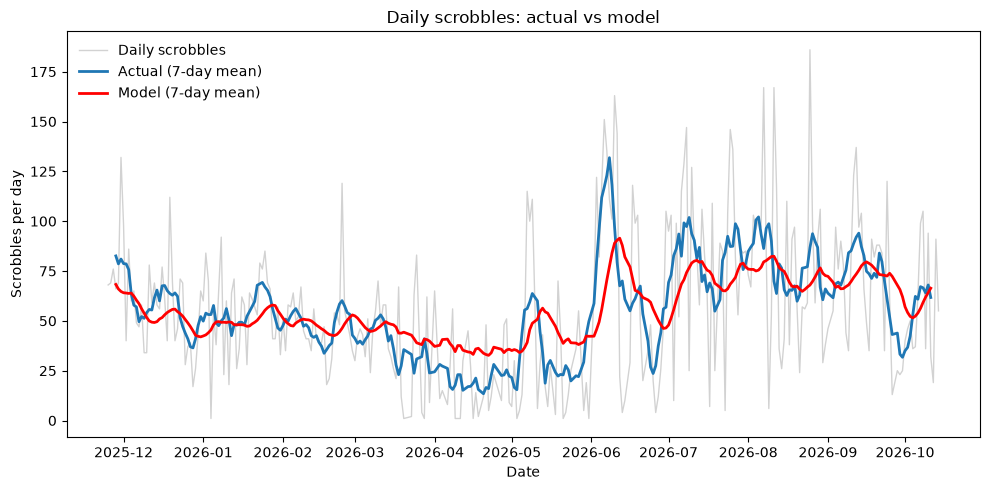

In [9]:
# refit the chosen model on all usable days and plot actual vs predicted (7-day rolling means for legibility)
daily['prev7'] = daily['scrobbles'].shift(1).rolling(7).mean()
data = daily.dropna().copy()

cols = days + ['holiday', 'daylight', 'annual', 'prev7']

model_B = LinearRegression(fit_intercept=False).fit(data[cols], data['scrobbles'])
data['predicted'] = model_B.predict(data[cols])


fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(data.index, data['scrobbles'], color="grey", alpha=0.35, lw=1, label='Daily scrobbles')
ax.plot(data.index, data['scrobbles'].rolling(7, center=True).mean(), lw=2, label='Actual (7-day mean)')
ax.plot(data.index, data['predicted'].rolling(7, center=True).mean(), color="red", lw=2, label='Model (7-day mean)')
ax.set(title='Daily scrobbles: actual vs model', xlabel='Date', ylabel='Scrobbles per day')
ax.legend(frameon=False, loc='upper left')
plt.tight_layout()
plt.show()

The data and the model predictions don't line up exactly. My listening comes in bursts, tied to whatever I'm doing at the time, and a calendar can't know that. Examples of what may have impacted the trends: internship, college work